In [1]:
import sympy as sp

In [12]:
x = sp.symbols('x', real=True)
m, hbar, alpha, beta = sp.symbols('m hbar alpha beta', real=True, positive=True)

In [14]:
def S_ij(psi_i, psi_j):
    return sp.integrate(psi_i * psi_j, (x, -sp.oo, sp.oo))
def T_ij(psi_i, psi_j):
    return hbar**2/(2*m) * sp.integrate(sp.diff(psi_i, x) * sp.diff(psi_j, x), (x, -sp.oo, sp.oo))
def V_ij(psi_i, psi_j, V):
    return sp.integrate(psi_i * V * psi_j, (x, -sp.oo, sp.oo))
def H_ij(psi_i, psi_j, V):
    return T_ij(psi_i, psi_j) + V_ij(psi_i, psi_j, V)


In [25]:
psi = sp.exp(-beta * x**2)
norm = sp.sqrt(S_ij(psi, psi))
psi = psi / norm
E = H_ij(psi, psi, alpha * x**4)
beta_opt = sp.solve(E.diff(beta), beta)[0]
beta_opt

6**(1/3)*alpha**(1/3)*m**(1/3)/(2*hbar**(2/3))

In [52]:
import numpy as np
from scipy.linalg import eigh

def variational(N, subs_dict):
    basis = [sp.exp(-beta_opt * x**2)*x**(2*n) for n in range(N)]
    S = sp.Matrix([[S_ij(psi_i, psi_j) for psi_j in basis] for psi_i in basis])
    H = sp.Matrix([[H_ij(psi_i, psi_j, alpha * x**4) for psi_j in basis] for psi_i in basis])
    H = H.subs(subs_dict)
    S = S.subs(subs_dict)
    H = np.array(H.evalf(), dtype=float)
    S = np.array(S.evalf(), dtype=float)
    eigvals, eigvecs = eigh(H, S)
    return eigvals

In [53]:
E_ground = [] 
for i in range(1,10):
    energies = variational(i,{alpha: 1, beta: 1, m: 1, hbar: 1})
    E_ground.append(energies[0])


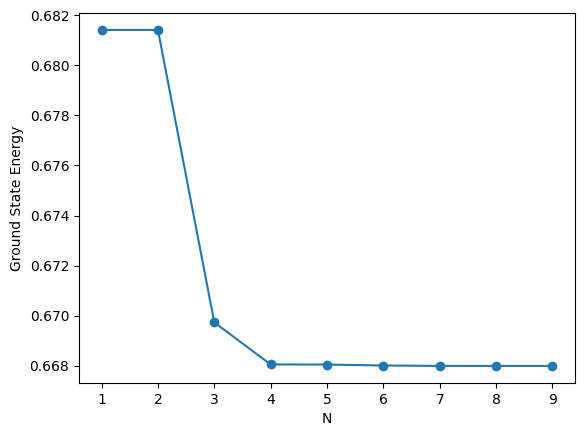

In [57]:
import matplotlib.pyplot as plt

plt.plot(range(1,10), E_ground, marker='o')
plt.xlabel('N')
plt.ylabel('Ground State Energy')
plt.show()